# Translate MDL files to python 

@Author: Georgia 
@Last Date: 2024-05/06


This notebook is designed to translate MDL files to Python. The goal is to create a script that can automatically convert Causal Loop Diagrams into Adjacency Matrixs which can then be used for network anlaysis.

A causal loop diagram (CLD) is a visual representation of the causal relationships between variables in a system. It is commonly used in system dynamics modeling to understand the feedback loops and dynamics of a complex system.

To achieve this, we will need to extract the necessary information from the MDL file, including the variables, their relationships, and the polarity of the relationships. We can then use this information to construct an adjacency matrix and a polarity matrix, which can be further analyzed using network analysis techniques.

In this example, I will show a basic exmple of an rabbit population CLD, and the translation to the matrixs. There is one reinforcing loop and one balancing loop in this CLD. Note there is a link between food and rabbit population without a defined polarity.
![Example Image](Testing/rabbit_cld.png)

We will turn this CLD into 3 three objects: 
1. Dict_vars: A dictionary of vairiable names and their index. 
2. Adj_matrix: An adjacency matrix that represents the connections between variables
3. Pol_matrix: A polarity matrix that represents the polarity of the connections



In [1]:
%load_ext autoreload
%autoreload 2

# Import library

In [2]:
import pandas as pd
import numpy as np
import regex as re
import networkx as nx
import itertools as it
import matplotlib.pyplot as plt

In [3]:
import parse_cld, cld_nx

# Read txt file of MDL file

In [4]:
with open('Testing/rabbit_example.mdl', 'r') as f:
    lines = f.readlines()
    
# Compile regex to match line with sketch info    

start_pattern = re.compile(r"\\\---///*") 
end_pattern = re.compile(r'\/{3}-+\\{3}')
                         
extracted = []
extract = False

for line in lines:
    if end_pattern.search(line):
        # Stop extracting if end pattern found
        extract = False

    elif start_pattern.search(line):
        # Start new extraction
        extracted = []
        extract = True

    elif extract:
        # Append to extracted lines
        extracted.append(line)

extracted = extracted[3:]
print(extracted)


['10,1,rabbit population,371,246,44,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '10,2,birth,532,268,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,3,1,2,1,0,43,0,0,192,0,-1--1--1,,1|(482,217)|\n', '1,4,2,1,1,0,43,0,0,192,0,-1--1--1,,1|(451,312)|\n', '10,5,deaths,203,245,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,6,1,5,1,0,43,0,0,192,0,-1--1--1,,1|(293,206)|\n', '1,7,5,1,1,0,45,0,0,192,0,-1--1--1,,1|(270,280)|\n', '10,8,food,418,148,42,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,9,8,1,0,0,0,0,0,192,0,-1--1--1,,1|(0,0)|\n', '10,10,fox population,330,362,61,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,11,1,10,1,0,0,0,0,192,0,-1--1--1,,1|(331,320)|\n', '10,12,numbers of hunts,170,420,44,22,8,3,0,0,-1,0,0,0,0,0,0,0,0,0\n', '1,13,10,12,1,0,43,0,0,192,0,-1--1--1,,1|(265,402)|\n']


In [5]:
df = pd.DataFrame(extracted)
df = df[0].str.split(',', expand = True)
# change column 0 dytpe to int
df[0] = df[0].astype(int)

# Grab dependencies 
df_links = df.loc[df[0]==1,  ]
df_links = df_links[[0,1, 2,3,6]]
df_links = df_links.rename(columns={0: 'variable type', 1: 'index',2: 'from', 3: 'to', 6: 'polarity'})
df_links['polarity'] = df_links['polarity'].astype(int)
df_links['links'] = 1
# In Column 6, it depicts, the polarity sign, 43 is positive, 45 is negative, and other values are unknown.

df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1,
                                     np.where(df_links['polarity'] == 45, -1, 3))

    
# df_links['polarity_type'] = np.where(df_links['polarity'] == 43, 1, -1)
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


In [6]:
# check datatype of df 
# for cols in df.columns:
#     print(df[cols].dtype)
#     

In [7]:
df_vars = df.loc[df[0]==10,  ]
# Create a dictionary based on  dataframe column 1 and 2
dict_var = df_vars.set_index(1)[2].to_dict()
dict_var


{'1': 'rabbit population',
 '2': 'birth',
 '5': 'deaths',
 '8': 'food',
 '10': 'fox population',
 '12': 'numbers of hunts'}

In [8]:
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


# Adjacency matrix: 

link_matrix[2: rabbit population] = 1 means that there is an arrow goes from birth to rabbit population. 

In [9]:
# Make an adjacency matrix and polarity matrix from df_links column from, to and links 
link_matrix = df_links.pivot(index='from', columns='to', values='links').fillna(0).astype(int)

In [10]:
link_matrix

to,1,10,12,2,5
from,,,,,
1,0,1,0,1,1
10,0,0,1,0,0
2,1,0,0,0,0
5,1,0,0,0,0
8,1,0,0,0,0


In [11]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(link_matrix.index) - set(link_matrix.columns)
missing_rows = set(link_matrix.columns) - set(link_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        link_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        link_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
link_matrix = link_matrix.sort_index(axis=1)
link_matrix = link_matrix.sort_index(axis = 0)
# link_matrix

In [12]:
# link_matrix.columns = link_matrix.columns.map(dict_var)
link_matrix

to,1,10,12,2,5,8
from,,,,,,
1,0,1,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,1,0,0,0,0,0
8,1,0,0,0,0,0


In [13]:
df_links

,variable type,index,from,to,polarity,links,polarity_type
2,1,3,1,2,43,1,1
3,1,4,2,1,43,1,1
5,1,6,1,5,43,1,1
6,1,7,5,1,45,1,-1
8,1,9,8,1,0,1,3
10,1,11,1,10,0,1,3
12,1,13,10,12,43,1,1


# Polarity matrix: 

link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population
link_matrix[2: rabbit population] = 1 means that there is an positive sign goes from birth to rabbit population. 
. 

In [14]:
polarity_matrix = df_links.pivot(index='from', columns = 'to', values = 'polarity_type').fillna(0).astype(int)


In [15]:
# get the number that exsits in link_matrix.index but does not exsist in link_matrix.columns
missing_cols = set(polarity_matrix.index) - set(polarity_matrix.columns)
missing_rows = set(polarity_matrix.columns) - set(polarity_matrix.index)

if len(missing_cols) > 0:
    for col in missing_cols:
        polarity_matrix[col] = 0
if len(missing_rows)> 0: 
    for row in missing_rows:
        polarity_matrix.loc[row] = 0

# Sort rows and cols by the index of dict_var
polarity_matrix = polarity_matrix.sort_index(axis=1)
polarity_matrix = polarity_matrix.sort_index(axis = 0)
polarity_matrix

to,1,10,12,2,5,8
from,,,,,,
1,0,3,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,-1,0,0,0,0,0
8,3,0,0,0,0,0


In [16]:
polarity_matrix.columns = polarity_matrix.columns.map(dict_var)

polarity_matrix

to,rabbit population,fox population,numbers of hunts,birth,deaths,food
from,,,,,,
1,0,3,0,1,1,0
10,0,0,1,0,0,0
12,0,0,0,0,0,0
2,1,0,0,0,0,0
5,-1,0,0,0,0,0
8,3,0,0,0,0,0


# NetworkX representation

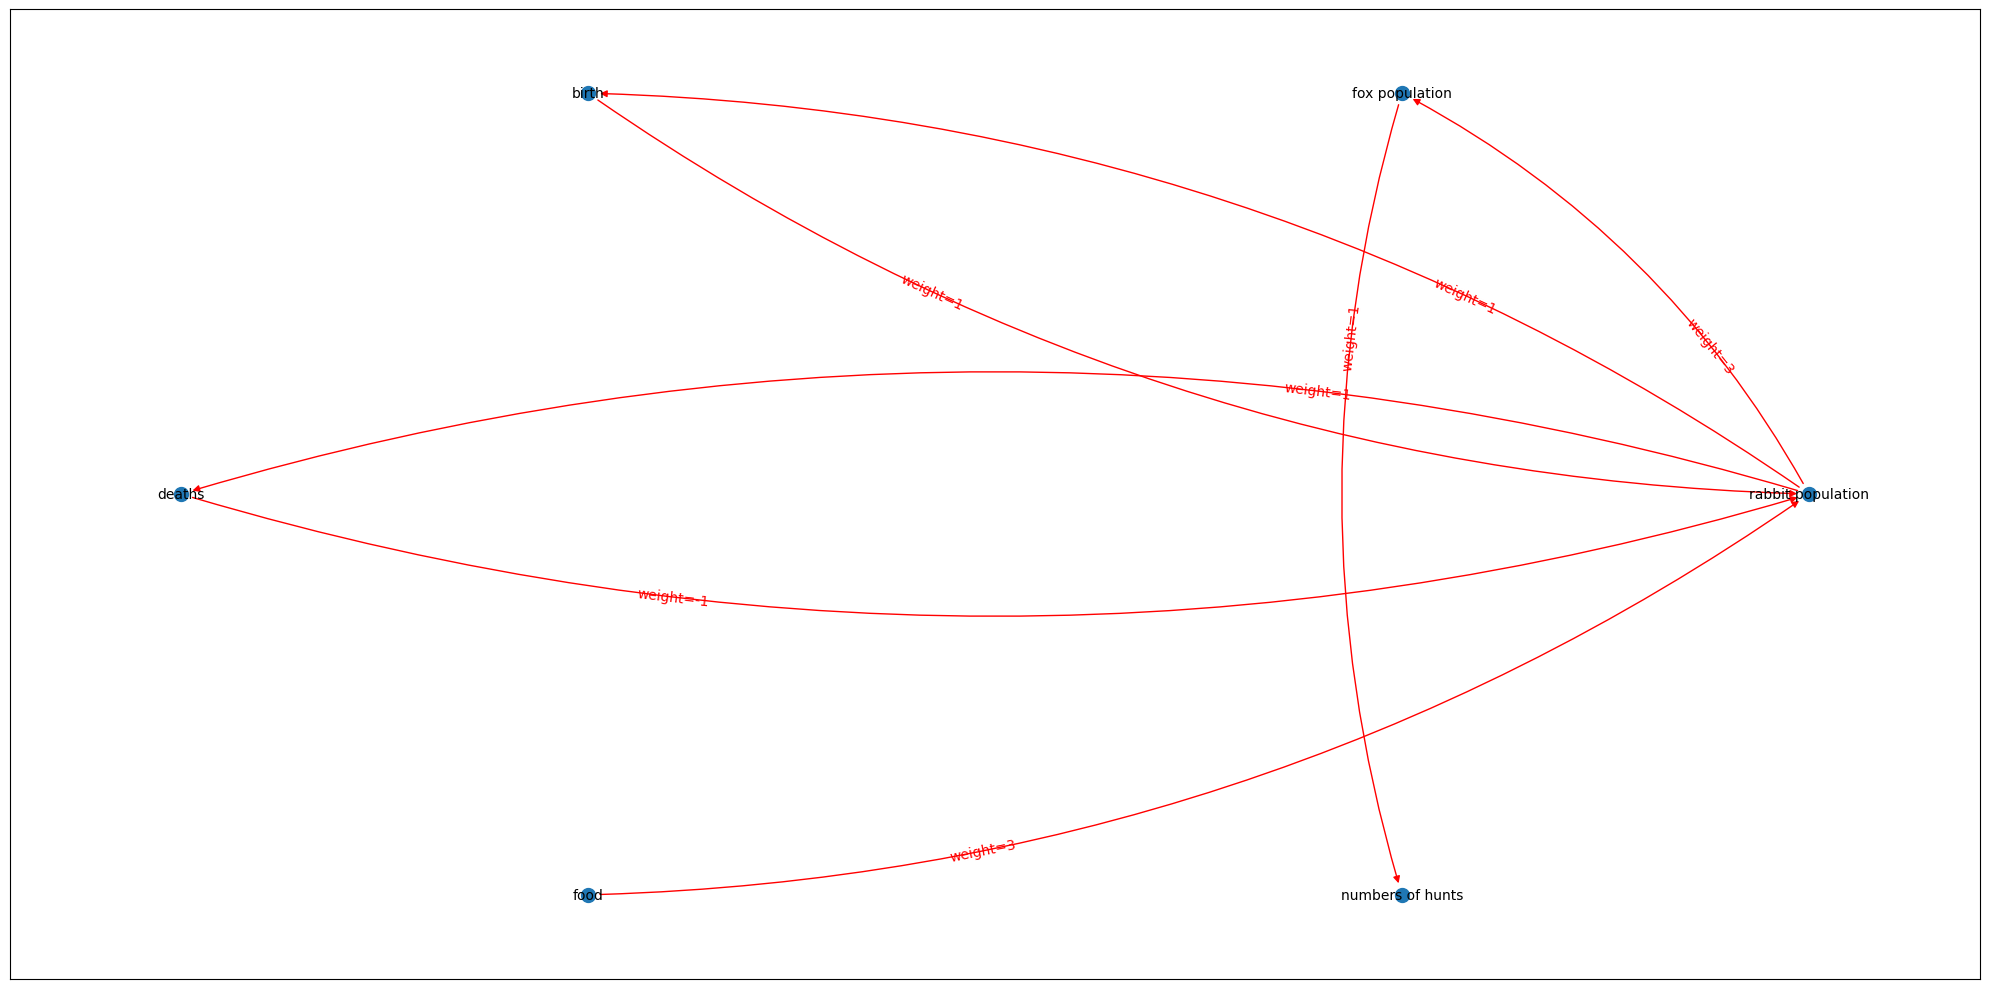

In [31]:
df_subset = df_links[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", dict_var)
plt.show()

In [18]:
# read json file 
import pickle
with open('Output/rabbit_example.json', 'rb') as f:
    loaded_dict = pickle.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'Output/rabbit_example.json'